# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

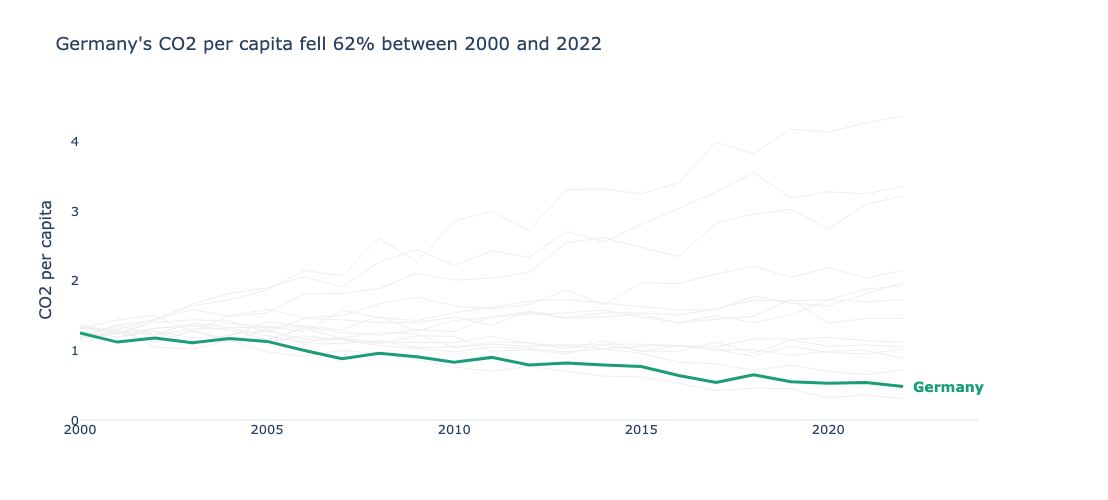

In [4]:
# Task 1 
# YOUR CODE HERE
def highlight_line_chart(data, y_col, highlight, colour, y_title, title):
    fig = go.Figure()

    for country in data['Country'].unique():       
        if country == highlight:                   
            continue
        d = data[data['Country'] == country].sort_values('Year') 
        fig.add_trace(go.Scatter(
            x=d['Year'],                           
            y=d[y_col],                            
            mode='lines',                          
            line=dict(color='#EEEEEE', width=1),  
            name=country,                          
            showlegend=False,                    
        ))

    
    d = data[data['Country'] == highlight].sort_values('Year') 
    fig.add_trace(go.Scatter(
        x=d['Year'], y=d[y_col],
        mode='lines',
        line=dict(color=colour, width=3),     
        name=highlight,
        showlegend=False,
    ))

    
    last = d.iloc[-1]                             
    fig.add_annotation(
        x=last['Year'], y=last[y_col],            
        text=f"<b>{highlight}</b>",                
        showarrow=False,                           
        xanchor='left',                            
        xshift=8,                                  
        font=dict(color=colour, size=14),          
    )

    # STEP 4: clean the look. Remove clutter.
    fig.update_layout(
        title=title,                               
        template='plotly_white',                   
        showlegend=False,                          
        yaxis_title=y_title,                       
        xaxis_title=None,                          
        font=dict(size=13),                        
        height=500,
        margin=dict(r=130),                        
    )
    fig.update_xaxes(range=[2000, 2024],           
                     showgrid=False,               
                     tickangle=0)                  
    fig.update_yaxes(showgrid=False,               
                     rangemode='tozero')           
    return fig                                     


star = 'Germany'                                   

g = df[df['Country'] == star]                      
start = g[g['Year'] == 2000]['CO2_per_capita'].iloc[0]   
end = g[g['Year'] == 2022]['CO2_per_capita'].iloc[0]     
change = (end / start - 1) * 100                  
word = 'fell' if change < 0 else 'rose'            

fig1 = highlight_line_chart(
    data=df,
    y_col='CO2_per_capita',
    highlight=star,
    colour='#1B9E77',
    y_title='CO2 per capita',
    title=f"{star}'s CO2 per capita {word} {abs(change):.0f}% between 2000 and 2022",
)
fig1.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

In [2]:
# Task 2 
# YOUR CODE HERE
# Task 2
# ------
# Keep only the rows where the Region column says 'Asia'.
asia = df[df['Region'] == 'Asia']
print(asia['Country'].unique())    # check which countries are inside, so you know what you're plotting

star2 = 'India'                    # your choice; it must be one of the countries printed above

# Compute the story from the data (same idea as Task 1).
i = asia[asia['Country'] == star2]
start2 = i[i['Year'] == 2000]['CO2_Mt'].iloc[0]    # emissions in 2000
end2 = i[i['Year'] == 2022]['CO2_Mt'].iloc[0]      # emissions in 2022
times = end2 / start2                               # how many times bigger

fig2 = highlight_line_chart(
    data=asia,                     # only Asian countries this time
    y_col='CO2_Mt',                # total emissions, in million tonnes
    highlight=star2,
    colour='#D95F02',
    y_title='CO2 emissions (Mt)',
    title=f"{star2}'s CO2 emissions grew {times:.1f}x between 2000 and 2022",
)
fig2.show()